# Etapa 5b · O professor aberto: uma LLM com os pesos em casa

| | |
|---|---|
| **Pergunta** | Quão bem uma LLM aberta, rodando nesta máquina, resolve a tarefa, e o que ela entrega que a fechada não entrega? |
| **Entrada** | `entregas/01_dados/`, `entregas/02_avaliacao/`, `entregas/04b_intencao/`, `entregas/05a_professor_fechado/` e as respostas dos modelos locais, gravadas pelos comandos de `especialista/experimentos/etapa5b.py`. |
| **Entrega** | `entregas/05b_professor_aberto/`: o treino rotulado pelo professor aberto, **os logits de intenção** de cada pedido do treino, as respostas em `dev` e teste, latência e tempo de GPU. |
| **Pronto quando** | (1) o professor foi escolhido em `dev` pela regra escrita antes; (2) todo pedido tem resposta e as 60 pontuações de intenção; (3) o professor está na régua, com intervalo, comparado de forma pareada com as referências e com o professor fechado; (4) os atalhos de cálculo foram conferidos contra a conta direta; (5) rótulos e logits estão gravados no formato que a destilação lê. |

**O que é "aberta".** Os pesos do modelo estão em disco e ele roda na placa de vídeo desta máquina. Não há API nem custo por pedido; há horas de GPU. E há acesso ao que o modelo calcula por dentro: além da intenção escolhida, a probabilidade que ele dá a **cada uma** das 60 intenções. É o cenário de **caixa-branca** da destilação. Na Etapa 6, o aluno B1 aprende com os rótulos deste professor e o aluno B2 com as probabilidades.

**Artigos de apoio**

- Probabilidades do professor como alvo do aluno, com temperatura: Hinton et al., *Distilling the Knowledge in a Neural Network* ([arXiv 1503.02531](https://arxiv.org/abs/1503.02531)).
- Destilação de LLMs, caixa-preta e caixa-branca: Xu et al. ([arXiv 2402.13116](https://arxiv.org/abs/2402.13116)).
- Os modelos candidatos: *Qwen3 Technical Report* ([arXiv 2505.09388](https://arxiv.org/abs/2505.09388)); *Gemma 3 Technical Report* ([arXiv 2503.19786](https://arxiv.org/abs/2503.19786)), na versão ajustada para português pelo CEIA-UFG ([GAIA](https://huggingface.co/CEIA-UFG/Gemma-3-Gaia-PT-BR-4b-it)).
- Pesos em 4 bits (NF4): Dettmers et al., *QLoRA* ([arXiv 2305.14314](https://arxiv.org/abs/2305.14314)).
- Calibração, o quanto a confiança de um modelo corresponde ao acerto: Guo et al., *On Calibration of Modern Neural Networks* ([arXiv 1706.04599](https://arxiv.org/abs/1706.04599)).
- LLMs em intenção e entidades: He & Garner ([arXiv 2305.13512](https://arxiv.org/abs/2305.13512)).

**Roteiro**

1. O que muda em relação à Etapa 5a
2. Como os logits saem do modelo
3. A escolha do professor
4. O professor na régua
5. Onde o professor erra
6. O que os logits trazem a mais
7. Os rótulos e os logits que o aluno vai receber
8. Latência e tempo de GPU
9. Entrega
10. Resposta

In [1]:
import json
import shutil
import warnings
from collections import Counter
from datetime import date

warnings.filterwarnings("ignore", message="IProgress not found")   # aviso da barra de progresso, que este notebook não usa

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from especialista import visual
from especialista.avaliacao import confianca, eficiencia, qualidade, resultados
from especialista.avaliacao.previsao import Previsao, carregar_previsoes, ouro, salvar_previsoes
from especialista.caminhos import ENTREGAS, RAIZ, entrega
from especialista.dados import massive
from especialista.experimentos import etapa5b
from especialista.modelos.linha_de_base import LinhaDeBase
from especialista.professores import claude
from especialista.professores.rotulagem import rotular

visual.aplicar_estilo()
pd.set_option("display.max_colwidth", 200)

PASTA = entrega("05b_professor_aberto")
SEMENTES = (0, 1, 2)
FECHADO = "Claude Haiku 5.5"

particoes, rotulos = massive.carregar_entrega()
treino, dev, teste = (particoes[p] for p in ("train", "dev", "test"))
intents, tipos = rotulos["intents"], rotulos["slot_types"]
coluna = {intent: i for i, intent in enumerate(intents)}
ouro_treino, ouro_dev, ouro_teste = ouro(treino), ouro(dev), ouro(teste)


def n(x):
    return f"{int(x):,}".replace(",", ".")


def num(x, casas=1):
    return f"{x:.{casas}f}".replace(".", ",")


def pts(x, casas=1):
    return num(100 * x, casas)


def dif(x):
    return f"{100 * x:+.1f}".replace(".", ",").replace("-", "−")


def com_intervalo(linha):
    return f"{dif(linha['diferenca'])} ({dif(linha['ic_min'])} a {dif(linha['ic_max'])})"


def valor_com_intervalo(linha):
    return f"{pts(linha['valor'])} ({pts(linha['ic_min'])} a {pts(linha['ic_max'])})"


def posicao(linha):
    """Onde B fica em relação a A numa comparação pareada B − A."""
    return "acima" if linha["ic_min"] > 0 else "abaixo" if linha["ic_max"] < 0 else "sem diferença distinguível"


def horas(segundos):
    return f"{int(segundos // 3600)} h {int(segundos % 3600 // 60):02d} min" if segundos >= 3600 else f"{segundos / 60:.0f} min"

## 1. O que muda em relação à Etapa 5a

| | Etapa 5a, professor fechado | Etapa 5b, professor aberto |
|---|---|---|
| Onde roda | no provedor, pela API | na placa de vídeo desta máquina |
| O que o professor vê | 299 exemplos com rótulo humano; em cada pedido, os 10 mais parecidos | o mesmo |
| Prompt e leitura da resposta | `professores/prompt.py` e `professores/resposta.py` | os mesmos |
| Formato da resposta | JSON imposto por um esquema, na geração | intenção escolhida entre as 60 pela probabilidade; entidades geradas livremente |
| O que se obtém | o texto da resposta | o texto da resposta **e** a probabilidade de cada intenção |
| Custo | dólares por pedido | horas de GPU |

Os modelos são carregados com os pesos em 4 bits (NF4), para caberem na placa de 10 GB. A resposta é sempre a mais provável a cada passo, sem sorteio: o mesmo pedido dá sempre a mesma resposta.

## 2. Como os logits saem do modelo

Um modelo de linguagem não responde "intenção 17". Ele escreve texto, um pedaço (token) por vez, e para cada pedaço calcula a probabilidade de todos os pedaços possíveis. A resposta de qualquer pedido começa igual: `{"intent": "`. Nesse ponto, mede-se a probabilidade de o modelo continuar com cada um dos 60 nomes de intenção.

Um nome ocupa vários tokens. A probabilidade do nome é o produto das probabilidades dos seus tokens, um depois do outro, até a aspa que o fecha:

In [2]:
candidatos = [apelido for apelido in etapa5b.CANDIDATOS if (etapa5b.pasta_das_respostas(apelido, "dev") / "respostas.jsonl").exists()]
lidos_dev = {apelido: etapa5b.previsoes(apelido, "dev") for apelido in candidatos}       # previsões, diagnóstico, registros
escolhido, disputas = etapa5b.escolher({apelido: lido[0] for apelido, lido in lidos_dev.items()})
PROFESSOR = etapa5b.CANDIDATOS[escolhido]["nome"]

from transformers import AutoTokenizer
tokenizador = AutoTokenizer.from_pretrained(etapa5b.CANDIDATOS[escolhido]["id"])
pedacos = lambda texto: [tokenizador.decode([t]) for t in tokenizador(texto, add_special_tokens=False).input_ids]
print("Como o tokenizador do", PROFESSOR, "quebra três nomes de intenção (com a aspa que fecha o nome):\n")
for intent in ("alarm_set", "email_query", "email_querycontact"):
    print(f"  {intent:20s}", pedacos('{"intent": "' + intent + '", "slots": [')[4:-4])
print("\nSem a aspa, `email_query` seria só o começo de `email_querycontact`.")

Como o tokenizador do Qwen3-8B quebra três nomes de intenção (com a aspa que fecha o nome):

  alarm_set            ['alarm', '_set', '",']
  email_query          ['email', '_query', '",']
  email_querycontact   ['email', '_query', 'contact', '",']

Sem a aspa, `email_query` seria só o começo de `email_querycontact`.


Um pedido de `dev` e o que o professor devolve para ele: o texto, como a LLM fechada, e as 60 pontuações. Abaixo, as cinco intenções mais prováveis.

In [3]:
logp_dev = np.array([r["logp"] for r in lidos_dev[escolhido][2]])
prob_dev = confianca.probabilidades(logp_dev)
exemplo = int(np.argmin(np.abs(prob_dev.max(axis=1) - 0.65)))   # um caso em que o modelo hesita
registro = lidos_dev[escolhido][2][exemplo]
print("Pedido:          ", dev.iloc[exemplo].utt)
print("Rótulo humano:   ", dev.iloc[exemplo].intent)
print("Resposta do", PROFESSOR + ":", registro["texto"])
maiores = np.argsort(-prob_dev[exemplo])[:5]
pd.DataFrame({
    "intenção": [intents[i] for i in maiores],
    "log-probabilidade (o que fica gravado)": [num(logp_dev[exemplo, i], 2) for i in maiores],
    "probabilidade": [pts(prob_dev[exemplo, i]) + "%" for i in maiores],
}, index=range(1, 6)).rename_axis("colocação")

Pedido:           avisar ao receber um email da casey
Rótulo humano:    email_query
Resposta do Qwen3-8B: {"intent": "email_sendemail", "slots": [{"type": "person", "text": "casey"}]}


,intenção,log-probabilidade (o que fica gravado),probabilidade
colocação,,,
1,email_sendemail,"-0,44","64,5%"
2,email_addcontact,"-1,19","30,5%"
3,email_query,"-3,63","2,6%"
4,email_querycontact,"-3,77","2,3%"
5,alarm_set,"-26,00","0,0%"


A LLM fechada entrega só a primeira linha dessa tabela, e sem o número. As outras linhas são o que a caixa-branca tem a mais.

**Três atalhos de cálculo.** Pontuar 60 nomes para cada um de 16.521 pedidos, do jeito direto, exigiria 60 passadas do prompt inteiro pelo modelo por pedido. O código faz três reaproveitamentos, todos baseados em guardar o que o modelo já calculou:

1. **As instruções são lidas uma vez.** Elas são iguais em todos os pedidos. É o mesmo que o cache de prompt da API fazia na Etapa 5a.
2. **O prompt é lido uma vez por pedido.** A pontuação das intenções e a geração das entidades partem do mesmo ponto.
3. **Os 60 nomes são pontuados numa passada só.** Os tokens de todos os nomes vão lado a lado, com uma máscara que impede cada nome de enxergar os outros.

Atalho que muda o resultado não serve. Por isso o código mantém também as contas diretas, sem nenhum reaproveitamento, e as duas foram comparadas nos mesmos pedidos:

In [4]:
conferencia = json.loads((etapa5b.pasta_das_respostas(escolhido, "conferencia.json")).read_text(encoding="utf-8"))
direta, biblioteca, lote = (conferencia[k] for k in ("pontuacao_rapida_contra_direta", "geracao_propria_contra_a_da_biblioteca", "em_lote_contra_um_a_um"))
q = conferencia["pedidos"]
pd.DataFrame([
    {"comparação": "Pontuação com os atalhos contra 60 passadas inteiras por pedido", "pedidos": direta["pedidos"],
     "resultado": f"maior diferença de probabilidade: {pts(direta['maior_diferenca_de_probabilidade'], 2)} ponto percentual; mesma intenção em {direta['mesma_intencao']} de {direta['pedidos']}"},
    {"comparação": "Geração própria contra a função `generate` da biblioteca", "pedidos": q,
     "resultado": f"mesma resposta, depois de lida, em {biblioteca['mesma_resposta_depois_de_lida']} de {q}; texto idêntico em {biblioteca['mesmo_texto']}"},
    {"comparação": f"Em lotes de {conferencia['lote']} contra um pedido por vez", "pedidos": q,
     "resultado": f"maior diferença de probabilidade: {pts(lote['maior_diferenca_de_probabilidade'])} pontos percentuais; mesma intenção em {lote['mesma_intencao']} de {q}; mesma resposta em {lote['mesma_resposta_depois_de_lida']}"},
]).set_index("comparação")

,pedidos,resultado
comparação,,
Pontuação com os atalhos contra 60 passadas inteiras por pedido,8,"maior diferença de probabilidade: 0,11 ponto percentual; mesma intenção em 8 de 8"
Geração própria contra a função `generate` da biblioteca,32,"mesma resposta, depois de lida, em 32 de 32; texto idêntico em 32"
Em lotes de 6 contra um pedido por vez,32,"maior diferença de probabilidade: 9,8 pontos percentuais; mesma intenção em 32 de 32; mesma resposta em 31"


As duas primeiras linhas conferem os atalhos. A terceira mostra um efeito que não vem dos atalhos: o modelo faz as contas em 16 bits, que guardam só três ou quatro algarismos, e processar vários pedidos juntos muda a ordem de algumas somas. Quando duas intenções ou dois tokens estão quase empatados, isso desloca a probabilidade e, às vezes, inverte a escolha. Os testes automáticos (`tests/test_professor_local.py`) repetem a conferência em 32 bits, com modelos pequenos de pesos sorteados, e lá a diferença some.

## 3. A escolha do professor

Três candidatos de acesso livre, todos em 4 bits. Cada um rotulou `dev` inteiro com o mesmo prompt.

**A regra, escrita antes de olhar os resultados** (em `etapa5b.escolher`): parte-se do candidato mais barato. Um candidato mais caro só toma o lugar se o exact match dele em `dev` for distinguivelmente maior, isto é, se o intervalo de 95% da diferença pareada ficar todo acima de zero.

,parâmetros (bilhões),memória na placa (GB),"s por pedido, em lote",Acurácia de intenção,Macro-F1 de intenção,F1 de entidades,Exact match,respostas sem aproveitamento,escolhido
candidato,,,,,,,,,
Qwen3-4B,"4,0","2,68","0,39","73,5","73,3","53,5","34,9",0,
GAIA 4B (CEIA-UFG),"4,3","3,23","0,34","71,1","71,7","50,7","38,6",12,
Qwen3-8B,"8,2","6,09","0,54","77,4","78,3","58,0","43,2",0,sim


As disputas, na ordem da regra (exact match em dev)


,titular,exact match do titular,exact match do desafiante,diferença (intervalo de 95%),toma o lugar
desafiante,,,,,
GAIA 4B (CEIA-UFG),Qwen3-4B,"34,9","38,6","+3,7 (+1,6 a +5,9)",sim
Qwen3-8B,GAIA 4B (CEIA-UFG),"38,6","43,2","+4,6 (+2,5 a +6,5)",sim


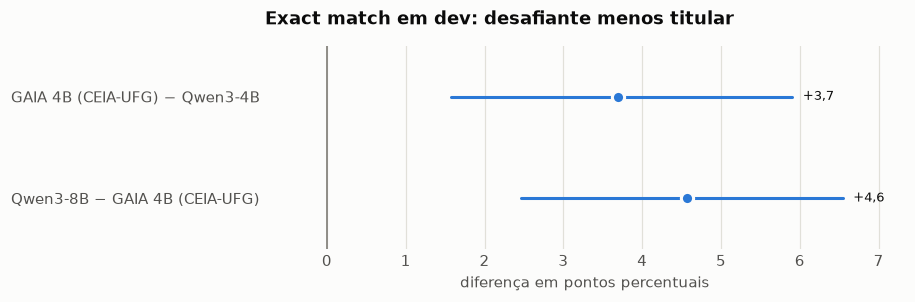

**Professor aberto do projeto: Qwen3-8B.**

In [5]:
medidas_dev = {apelido: qualidade.avaliar(ouro_dev, lido[0]) for apelido, lido in lidos_dev.items()}
parametros = {apelido: etapa5b.parametros_do_modelo(apelido) for apelido in candidatos}   # lidos dos arquivos de pesos
metas_dev = {apelido: json.loads((etapa5b.pasta_das_respostas(apelido, "dev") / "meta.json").read_text(encoding="utf-8")) for apelido in candidatos}
quadro_dos_candidatos = pd.DataFrame([
    {
        "candidato": etapa5b.CANDIDATOS[a]["nome"],
        "parâmetros (bilhões)": num(parametros[a] / 1e9, 1),
        "memória na placa (GB)": num(metas_dev[a]["vram_do_modelo_gb"], 2),
        "s por pedido, em lote": num(metas_dev[a]["segundos_de_gpu"] / metas_dev[a]["pedidos"], 2),
        **{qualidade.NOMES[m]: pts(medidas_dev[a][m]) for m in qualidade.METRICAS},
        "respostas sem aproveitamento": lidos_dev[a][1]["sem_resposta"] + lidos_dev[a][1]["json_invalido"],
        "escolhido": "sim" if a == escolhido else "",
    }
    for a in candidatos
]).set_index("candidato")
display(quadro_dos_candidatos)

linhas = []
for desafiante, d in disputas.items():
    linhas.append({
        "desafiante": etapa5b.CANDIDATOS[desafiante]["nome"], "titular": etapa5b.CANDIDATOS[d["contra"]]["nome"],
        "exact match do titular": pts(d["a"]), "exact match do desafiante": pts(d["b"]),
        "diferença (intervalo de 95%)": com_intervalo(d), "toma o lugar": "sim" if d["ic_min"] > 0 else "não",
    })
print("As disputas, na ordem da regra (exact match em dev)")
display(pd.DataFrame(linhas).set_index("desafiante"))

if disputas:
    fig, ax = visual.diferencas_com_intervalo(
        {f"{etapa5b.CANDIDATOS[a]['nome']} − {etapa5b.CANDIDATOS[d['contra']]['nome']}": tuple(100 * d[c] for c in ("diferenca", "ic_min", "ic_max")) for a, d in disputas.items()},
        "Exact match em dev: desafiante menos titular", "diferença em pontos percentuais",
    )
    visual.salvar(fig, PASTA, "escolha_do_professor")
    plt.show()
display(Markdown(f"**Professor aberto do projeto: {PROFESSOR}.**"))

### Um detalhe de formato que mudou o resultado

Depois de escolher a intenção, o código escreve o começo do resto da resposta e o modelo continua. Na primeira versão, esse começo ia até o colchete que abre a lista de entidades: `", "slots": [`. Parecia inofensivo. Não era: para uma lista vazia o modelo escreve `[]` como um token só, e com o `[` já escrito ele ficava fora do que conhece. Os três candidatos tinham rotulado `dev` inteiro assim antes de o defeito aparecer. A tabela compara essas medidas com as da versão final, que força só até `"slots":`.

In [6]:
arquivo_do_colchete = etapa5b.PASTA / "colchete_forcado.json"
if not arquivo_do_colchete.exists():
    arquivo_do_colchete = PASTA / "respostas" / "colchete_forcado.json"
colchete = json.loads(arquivo_do_colchete.read_text(encoding="utf-8"))
antes = colchete["dev_inteiro_com_o_colchete"]
linhas = []
for a in candidatos:
    devolvidas = lidos_dev[a][1]["entidades"]
    linhas.append({
        "candidato": etapa5b.CANDIDATOS[a]["nome"],
        "exact match com o colchete": pts(antes[a]["exact_match"]), "exact match sem": pts(medidas_dev[a]["exact_match"]),
        "ganho": dif(medidas_dev[a]["exact_match"] - antes[a]["exact_match"]),
        "intenção com": pts(antes[a]["intent_acc"]), "intenção sem": pts(medidas_dev[a]["intent_acc"]),
        "entidades devolvidas com": n(antes[a]["entidades_devolvidas"]), "entidades devolvidas sem": n(devolvidas),
        "respostas sem aproveitamento com": antes[a]["respostas_sem_aproveitamento"],
        "respostas sem aproveitamento sem": lidos_dev[a][1]["sem_resposta"] + lidos_dev[a][1]["json_invalido"],
    })
ganho_do_escolhido = medidas_dev[escolhido]["exact_match"] - antes[escolhido]["exact_match"]
display(pd.DataFrame(linhas).set_index("candidato"))
display(Markdown(f"""
Os rótulos humanos de `dev` têm {n(sum(len(o.slots) for o in ouro_dev))} entidades. Com o colchete forçado, os modelos devolviam entidades de sobra e parte das respostas saía inválida. Só essa mudança de um caractere no texto forçado valeu **{dif(ganho_do_escolhido)} pontos** de exact match para o {PROFESSOR}. É um lembrete de que, numa LLM, o formato pedido faz parte do método e precisa ser medido como o resto.
"""))

,exact match com o colchete,exact match sem,ganho,intenção com,intenção sem,entidades devolvidas com,entidades devolvidas sem,respostas sem aproveitamento com,respostas sem aproveitamento sem
candidato,,,,,,,,,
Qwen3-4B,"27,3","34,9","+7,6","72,6","73,5",3.125,2.835,20,0
GAIA 4B (CEIA-UFG),"28,0","38,6","+10,6","69,0","71,1",2.350,1.607,81,12
Qwen3-8B,"28,9","43,2","+14,3","68,8","77,4",2.707,2.489,203,0



Os rótulos humanos de `dev` têm 2.000 entidades. Com o colchete forçado, os modelos devolviam entidades de sobra e parte das respostas saía inválida. Só essa mudança de um caractere no texto forçado valeu **+14,3 pontos** de exact match para o Qwen3-8B. É um lembrete de que, numa LLM, o formato pedido faz parte do método e precisa ser medido como o resto.


## 4. O professor na régua

A partir daqui, só o professor escolhido. Ele rotulou também o teste e o treino.

In [7]:
lidos = {"dev": lidos_dev[escolhido], "test": etapa5b.previsoes(escolhido, "test"), "train": etapa5b.previsoes(escolhido, "train")}
aberto_dev, aberto_teste, aberto_treino = (lidos[c][0] for c in ("dev", "test", "train"))
nome_de = {"dev": "dev", "test": "teste", "train": "treino"}

linhas = []
for conjunto, (_, d, registros) in lidos.items():
    linhas.append({
        "conjunto": nome_de[conjunto], "pedidos": len(registros), "sem registro": d["sem_registro"],
        "resposta cortada (não fechou o JSON)": d["sem_resposta"] - d["sem_registro"], "JSON ilegível": d["json_invalido"],
        "entidades devolvidas": d["entidades"], "tipo fora da lista": d["tipo_fora_da_lista"], "texto que não está no pedido": d["texto_nao_encontrado"],
    })
leitura = pd.DataFrame(linhas).set_index("conjunto")
leitura.loc["total"] = leitura.sum()
total = leitura.loc["total"]
sem_uso = int(total["sem registro"] + total["resposta cortada (não fechou o JSON)"] + total["JSON ilegível"])
perdidas = int(total["tipo fora da lista"] + total["texto que não está no pedido"])
display(leitura.map(n))
display(Markdown(f"""
**Leitura.** A intenção nunca sai da lista, porque é escolhida entre as 60 pela probabilidade. As entidades são geradas livremente, e é aí que este professor perde o que a LLM fechada não perdia: de {n(total['entidades devolvidas'])} entidades devolvidas, **{n(perdidas)}** ({pts(perdidas / total['entidades devolvidas'], 2)}%) foram descartadas, {n(total['tipo fora da lista'])} por tipo fora da lista e {n(total['texto que não está no pedido'])} por texto que não está no pedido. Respostas sem aproveitamento: {n(sem_uso)} de {n(total['pedidos'])}.
"""))

,pedidos,sem registro,resposta cortada (não fechou o JSON),JSON ilegível,entidades devolvidas,tipo fora da lista,texto que não está no pedido
conjunto,,,,,,,
dev,2.033,0,0,0,2.489,92,52
teste,2.974,0,0,7,3.515,119,86
treino,11.514,0,0,11,14.046,532,259
total,16.521,0,0,18,20.050,743,397



**Leitura.** A intenção nunca sai da lista, porque é escolhida entre as 60 pela probabilidade. As entidades são geradas livremente, e é aí que este professor perde o que a LLM fechada não perdia: de 20.050 entidades devolvidas, **1.140** (5,69%) foram descartadas, 743 por tipo fora da lista e 397 por texto que não está no pedido. Respostas sem aproveitamento: 18 de 16.521.


In [8]:
medida_dev, medida_teste = qualidade.intervalo(ouro_dev, aberto_dev), qualidade.intervalo(ouro_teste, aberto_teste)
print("O professor aberto sozinho, em % (intervalo de 95%)")
display(pd.DataFrame({
    "dev": [valor_com_intervalo(l) for _, l in medida_dev.iterrows()],
    "teste": [valor_com_intervalo(l) for _, l in medida_teste.iterrows()],
}, index=medida_dev.index).rename(index=qualidade.NOMES))

ETAPA5A = ENTREGAS / "05a_professor_fechado"
referencias = {}
for particao in ("dev", "test"):
    referencias[particao] = {
        "Linha de base com 11.514 rótulos": [carregar_previsoes(ENTREGAS / "02_avaliacao" / "previsoes" / f"linha_de_base_{particao}.parquet")[1]],
        "Rede do zero com 11.514 rótulos": [carregar_previsoes(ENTREGAS / "04b_intencao" / "previsoes" / f"semente_{s}_{particao}.parquet")[1] for s in SEMENTES],
        f"{FECHADO} (professor fechado)": [carregar_previsoes(ETAPA5A / "previsoes" / f"claude_{particao}.parquet")[1]],
    }
gabarito = {"dev": ouro_dev, "test": ouro_teste}
do_professor = {"dev": aberto_dev, "test": aberto_teste}
contra = {p: {ref: qualidade.comparar_grupos(gabarito[p], grupo, [do_professor[p]]) for ref, grupo in referencias[p].items()} for p in ("dev", "test")}

# a primeira leitura da Etapa 5a, repetida aqui: o professor acrescenta algo aos 299 rótulos que ele vê?
demonstracoes = pd.read_parquet(ETAPA5A / "demonstracoes.parquet")
base_299 = LinhaDeBase(caracteres=True).treinar(demonstracoes)
contra_299 = qualidade.comparar(ouro_dev, base_299.prever(list(dev["utt"])), aberto_dev).loc["exact_match"]

colunas = {ref: tabela["a"].map(pts) for ref, tabela in contra["test"].items()}
colunas[PROFESSOR] = next(iter(contra["test"].values()))["b"].map(pts)
print("Teste: valor de cada sistema (%)")
display(pd.DataFrame(colunas).loc[list(qualidade.METRICAS)].rename(index=qualidade.NOMES))
print("Teste: professor aberto menos referência, em pontos percentuais (intervalo de 95%)")
pd.DataFrame({ref: [com_intervalo(l) for _, l in tabela.loc[list(qualidade.METRICAS)].iterrows()] for ref, tabela in contra["test"].items()},
             index=[qualidade.NOMES[m] for m in qualidade.METRICAS])

O professor aberto sozinho, em % (intervalo de 95%)


,dev,teste
Acurácia de intenção,"77,4 (75,7 a 79,2)","77,6 (76,1 a 79,1)"
Macro-F1 de intenção,"78,3 (75,9 a 80,6)","76,6 (74,7 a 79,2)"
Precisão de entidades,"53,7 (51,5 a 55,9)","51,5 (49,6 a 53,3)"
Recall de entidades,"62,9 (60,7 a 65,2)","60,7 (58,8 a 62,7)"
F1 de entidades,"58,0 (55,9 a 60,1)","55,7 (53,9 a 57,4)"
Exact match,"43,2 (41,0 a 45,3)","43,2 (41,5 a 45,0)"


Teste: valor de cada sistema (%)


,Linha de base com 11.514 rótulos,Rede do zero com 11.514 rótulos,Claude Haiku 5.5 (professor fechado),Qwen3-8B
Acurácia de intenção,"84,6","84,4","83,5","77,6"
Macro-F1 de intenção,"81,4","82,8","82,1","76,6"
F1 de entidades,"47,8","73,6","66,1","55,7"
Exact match,"45,2","62,5","54,0","43,2"


Teste: professor aberto menos referência, em pontos percentuais (intervalo de 95%)


,Linha de base com 11.514 rótulos,Rede do zero com 11.514 rótulos,Claude Haiku 5.5 (professor fechado)
Acurácia de intenção,"−7,0 (−8,5 a −5,5)","−6,8 (−8,2 a −5,4)","−5,9 (−7,2 a −4,5)"
Macro-F1 de intenção,"−4,8 (−7,3 a −2,1)","−6,2 (−8,2 a −4,0)","−5,5 (−7,2 a −3,8)"
F1 de entidades,"+7,9 (+5,7 a +10,1)","−18,0 (−19,7 a −16,2)","−10,4 (−11,9 a −8,9)"
Exact match,"−2,0 (−4,1 a +0,1)","−19,2 (−21,1 a −17,5)","−10,8 (−12,4 a −9,1)"


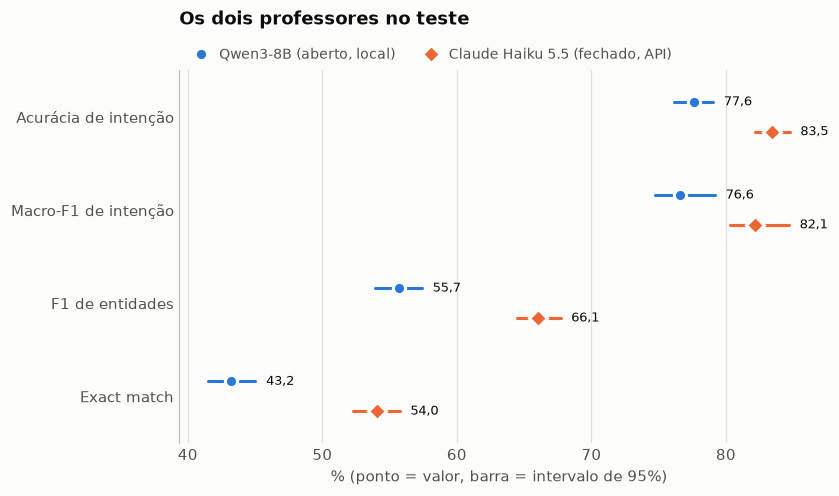


**Leitura.**

- **O professor acrescenta algo aos 299 rótulos que ele vê?** Sim. Em `dev`, o exact match dele é 43,2% e o da linha de base treinada com os mesmos 299 rótulos é 20,2%: +23,0 (+20,6 a +25,4) pontos.
- **Contra o professor fechado, no teste:** intenção abaixo (−5,9 (−7,2 a −4,5)), entidades abaixo (−10,4 (−11,9 a −8,9)), exact match abaixo (−10,8 (−12,4 a −9,1)).
- **Contra a rede do zero com todos os rótulos humanos, no teste:** intenção abaixo (−6,8 (−8,2 a −5,4)), entidades abaixo (−18,0 (−19,7 a −16,2)), exact match abaixo (−19,2 (−21,1 a −17,5)).
- **Contra a linha de base com todos os rótulos humanos, no teste:** exact match sem diferença distinguível (−2,0 (−4,1 a +0,1)).


In [9]:
fechado_teste = qualidade.intervalo(ouro_teste, referencias["test"][f"{FECHADO} (professor fechado)"][0])
fig, ax = visual.pontos_com_intervalo(
    {
        f"{PROFESSOR} (aberto, local)": {qualidade.NOMES[m]: tuple(100 * medida_teste.loc[m, c] for c in ("valor", "ic_min", "ic_max")) for m in qualidade.METRICAS},
        f"{FECHADO} (fechado, API)": {qualidade.NOMES[m]: tuple(100 * fechado_teste.loc[m, c] for c in ("valor", "ic_min", "ic_max")) for m in qualidade.METRICAS},
    },
    "Os dois professores no teste", "% (ponto = valor, barra = intervalo de 95%)",
)
visual.salvar(fig, PASTA, "os_dois_professores")
plt.show()

contra_fechado = contra["test"][f"{FECHADO} (professor fechado)"]
contra_rede = contra["test"]["Rede do zero com 11.514 rótulos"]
contra_base = contra["test"]["Linha de base com 11.514 rótulos"]
display(Markdown(f"""
**Leitura.**

- **O professor acrescenta algo aos {len(demonstracoes)} rótulos que ele vê?** {"Sim" if contra_299["ic_min"] > 0 else "Não"}. Em `dev`, o exact match dele é {pts(contra_299["b"])}% e o da linha de base treinada com os mesmos {len(demonstracoes)} rótulos é {pts(contra_299["a"])}%: {com_intervalo(contra_299)} pontos.
- **Contra o professor fechado, no teste:** intenção {posicao(contra_fechado.loc['intent_acc'])} ({com_intervalo(contra_fechado.loc['intent_acc'])}), entidades {posicao(contra_fechado.loc['slot_f1'])} ({com_intervalo(contra_fechado.loc['slot_f1'])}), exact match {posicao(contra_fechado.loc['exact_match'])} ({com_intervalo(contra_fechado.loc['exact_match'])}).
- **Contra a rede do zero com todos os rótulos humanos, no teste:** intenção {posicao(contra_rede.loc['intent_acc'])} ({com_intervalo(contra_rede.loc['intent_acc'])}), entidades {posicao(contra_rede.loc['slot_f1'])} ({com_intervalo(contra_rede.loc['slot_f1'])}), exact match {posicao(contra_rede.loc['exact_match'])} ({com_intervalo(contra_rede.loc['exact_match'])}).
- **Contra a linha de base com todos os rótulos humanos, no teste:** exact match {posicao(contra_base.loc['exact_match'])} ({com_intervalo(contra_base.loc['exact_match'])}).
"""))

## 5. Onde o professor erra

Em `dev`, como na Etapa 5a, e com os mesmos recortes, para os dois professores ficarem lado a lado.

In [10]:
def acertos(gabarito, previsoes):
    intencao = np.array([p.intent == o.intent for o, p in zip(gabarito, previsoes)])
    entidades = np.array([set(p.slots) == set(o.slots) for o, p in zip(gabarito, previsoes)])
    return intencao, entidades


def reparticao(gabarito, previsoes):
    intencao, entidades = acertos(gabarito, previsoes)
    return pd.Series({
        "Tudo certo (exact match)": (intencao & entidades).mean(),
        "Só a intenção errada": (~intencao & entidades).mean(),
        "Só as entidades erradas": (intencao & ~entidades).mean(),
        "Intenção e entidades erradas": (~intencao & ~entidades).mean(),
    })


fechado_dev = referencias["dev"][f"{FECHADO} (professor fechado)"][0]
rede_dev = referencias["dev"]["Rede do zero com 11.514 rótulos"]
partes = pd.DataFrame({
    PROFESSOR: reparticao(ouro_dev, aberto_dev),
    FECHADO: reparticao(ouro_dev, fechado_dev),
    "Rede do zero (média de 3 sementes)": sum(reparticao(ouro_dev, p) for p in rede_dev) / len(rede_dev),
})
display(partes.map(lambda v: pts(v) + "%"))

destinos = pd.DataFrame({
    PROFESSOR: qualidade.erros_de_entidade(ouro_dev, aberto_dev),
    FECHADO: qualidade.erros_de_entidade(ouro_dev, fechado_dev),
    "Rede do zero (média de 3 sementes)": sum(qualidade.erros_de_entidade(ouro_dev, p) for p in rede_dev) / len(rede_dev),
})
entidades_em_dev = int(destinos[PROFESSOR][list(qualidade.DESTINOS)].sum())
nomes_dos_destinos = {
    "certa": "Certa", "limite diferente": "Limite diferente", "tipo diferente": "Tipo diferente",
    "tipo e limite diferentes": "Tipo e limite diferentes", "faltou": "Faltou", "a mais": "A mais (não está nos rótulos)",
}
print(f"O que aconteceu com cada uma das {n(entidades_em_dev)} entidades dos rótulos humanos de dev")
destinos.rename(index=nomes_dos_destinos).map(lambda v: f"{n(round(v))} ({pts(v / entidades_em_dev)}%)")

,Qwen3-8B,Claude Haiku 5.5,Rede do zero (média de 3 sementes)
Tudo certo (exact match),"43,2%","54,7%","62,6%"
Só a intenção errada,"7,6%","7,3%","9,4%"
Só as entidades erradas,"34,2%","29,4%","21,3%"
Intenção e entidades erradas,"15,0%","8,6%","6,7%"


O que aconteceu com cada uma das 2.000 entidades dos rótulos humanos de dev


,Qwen3-8B,Claude Haiku 5.5,Rede do zero (média de 3 sementes)
Certa,"1.259 (62,9%)","1.439 (72,0%)","1.531 (76,5%)"
Limite diferente,"242 (12,1%)","223 (11,2%)","181 (9,0%)"
Tipo diferente,"164 (8,2%)","105 (5,2%)","68 (3,4%)"
Tipo e limite diferentes,"117 (5,9%)","60 (3,0%)","59 (2,9%)"
Faltou,"218 (10,9%)","173 (8,6%)","162 (8,1%)"
A mais (não está nos rótulos),"565 (28,2%)","368 (18,4%)","205 (10,3%)"


In [11]:
certa = np.array([o.intent for o in ouro_dev])
dada = np.array([p.intent for p in aberto_dev])
trocas = pd.Series(Counter(zip(certa[certa != dada], dada[certa != dada]))).sort_values(ascending=False)
print(f"As 8 trocas de intenção mais frequentes do professor aberto em dev ({n((certa != dada).sum())} erros de intenção no total)")
display(pd.DataFrame({
    "rótulo humano": [par[0] for par in trocas.index[:8]],
    "resposta do professor": [par[1] for par in trocas.index[:8]],
    "vezes": trocas.to_numpy()[:8],
    "um exemplo": [dev["utt"].to_numpy()[(certa == par[0]) & (dada == par[1])][0] for par in trocas.index[:8]],
}))

# os dois professores erram nos mesmos pedidos?
tudo_aberto = np.array([p == o for o, p in zip(ouro_dev, aberto_dev)])
tudo_fechado = np.array([p == o for o, p in zip(ouro_dev, fechado_dev)])
acordo = pd.Series({
    "Os dois acertam tudo": (tudo_aberto & tudo_fechado).mean(),
    f"Só o {FECHADO} acerta tudo": (~tudo_aberto & tudo_fechado).mean(),
    f"Só o {PROFESSOR} acerta tudo": (tudo_aberto & ~tudo_fechado).mean(),
    "Nenhum dos dois acerta tudo": (~tudo_aberto & ~tudo_fechado).mean(),
})
mesma_resposta = np.mean([a == f for a, f in zip(aberto_dev, fechado_dev)])
print(f"Os dois professores dão exatamente a mesma resposta em {pts(mesma_resposta)}% dos pedidos de dev.")
acordo.map(lambda v: pts(v) + "%").rename("parte de dev").to_frame()

As 8 trocas de intenção mais frequentes do professor aberto em dev (459 erros de intenção no total)


,rótulo humano,resposta do professor,vezes,um exemplo
0,qa_factoid,general_quirky,15,quão alta é uma girafa
1,calendar_set,calendar_query,14,por favor adicionar a minha próxima reunião
2,qa_factoid,recommendation_locations,11,onde o centro de convenção está situado
3,qa_factoid,news_query,10,quais são os edifícios mais longos do mundo
4,play_music,music_query,10,alguns david bowie
5,email_query,email_querycontact,10,digam-me quem enviou ontem o e-mail sobre o chefe
6,general_quirky,qa_factoid,8,dá me respostas
7,calendar_query,recommendation_events,8,próximos eventos


Os dois professores dão exatamente a mesma resposta em 53,1% dos pedidos de dev.


,parte de dev
Os dois acertam tudo,"38,4%"
Só o Claude Haiku 5.5 acerta tudo,"16,4%"
Só o Qwen3-8B acerta tudo,"4,8%"
Nenhum dos dois acerta tudo,"40,4%"


## 6. O que os logits trazem a mais

Esta é a parte que só existe na caixa-branca. Três perguntas sobre as 60 probabilidades, medidas em `dev`.

### 6.1 A confiança do professor diz alguma coisa?

Se o professor dá 95% a uma intenção, ele acerta 95% das vezes? Os pedidos de `dev` são agrupados pela confiança na intenção escolhida, em faixas de 10 pontos. Em cada faixa, compara-se a confiança média com a acurácia.

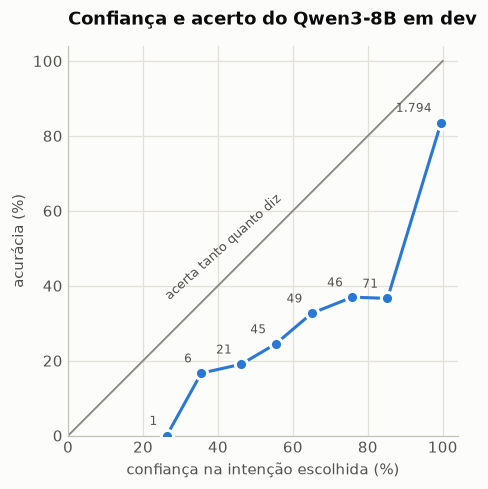

,pedidos,confiança média,acurácia
faixa de confiança,,,
20% a 30%,1,"26,3%","0,0%"
30% a 40%,6,"35,5%","16,7%"
40% a 50%,21,"46,2%","19,0%"
50% a 60%,45,"55,4%","24,4%"
60% a 70%,49,"65,0%","32,7%"
70% a 80%,46,"75,9%","37,0%"
80% a 90%,71,"85,2%","36,6%"
90% a 100%,1.794,"99,6%","83,6%"


In [12]:
certa_dev = np.array([coluna[o.intent] for o in ouro_dev])
escolhida_dev = prob_dev.argmax(axis=1)
acertou_dev = escolhida_dev == certa_dev
confianca_dev = prob_dev.max(axis=1)
faixas = confianca.faixas_de_confianca(confianca_dev, acertou_dev)
ece = confianca.erro_de_calibracao(faixas)

fig, ax = visual.calibracao(faixas, f"Confiança e acerto do {PROFESSOR} em dev")
visual.salvar(fig, PASTA, "calibracao")
plt.show()

muito_confiante = confianca_dev >= 0.9
pouco_confiante = confianca_dev < 0.5
pd.DataFrame({
    "faixa de confiança": [f"{pts(l['de'], 0)}% a {pts(l['ate'], 0)}%" for _, l in faixas.iterrows()],
    "pedidos": faixas["pedidos"].map(n),
    "confiança média": faixas["confianca"].map(lambda v: pts(v) + "%"),
    "acurácia": faixas["acuracia"].map(lambda v: pts(v) + "%"),
}).set_index("faixa de confiança")

### 6.2 Quando o professor erra a intenção, a certa está logo atrás?

Um rótulo rígido só diz qual intenção ficou em primeiro. As probabilidades dizem também quais ficaram em segundo e terceiro.

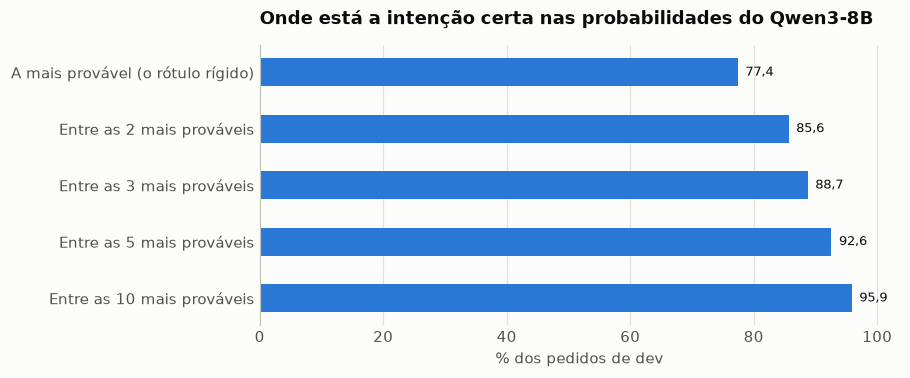


**Leitura das duas medidas.**

- **A confiança separa acerto de erro.** Nos 1.794 pedidos em que o professor dá 90% ou mais à intenção escolhida (88,2% de `dev`), ele acerta 83,6%. Nos 28 em que dá menos de 50%, acerta 17,9%. Um aluno que recebe a probabilidade sabe em quais rótulos confiar menos; um aluno que recebe só o rótulo, não.
- **A confiança é exagerada.** A confiança média é 95,9% e a acurácia é 77,4%. O erro de calibração esperado (ECE) é de 18,5 pontos. É para isso que a destilação usa temperatura: ela espalha a probabilidade antes de o aluno vê-la.
- **A resposta certa costuma estar perto.** O professor acerta a intenção em 77,4% dos pedidos; em 88,7% a certa está entre as 3 mais prováveis e em 92,6% entre as 5. Nos 459 erros, a intenção certa é a 2ª colocada em 36,4% e recebe, na mediana, 0,01% de probabilidade.
- **A dúvida aparece nos números.** A entropia, que mede o quanto a probabilidade está espalhada, tem mediana de 0,000 bit quando o professor acerta e de 0,215 bit quando erra (o máximo, com as 60 intenções igualmente prováveis, seria 5,91).


In [13]:
entre_as_k = confianca.acerto_entre_as_k(prob_dev, certa_dev)
fig, ax = visual.barras_em_ordem(
    {("A mais provável (o rótulo rígido)" if k == 1 else f"Entre as {k} mais prováveis"): 100 * v for k, v in entre_as_k.items()},
    f"Onde está a intenção certa nas probabilidades do {PROFESSOR}", "% dos pedidos de dev",
)
visual.salvar(fig, PASTA, "entre_as_k")
plt.show()

erros = ~acertou_dev
prob_da_certa_nos_erros = prob_dev[erros, certa_dev[erros]]
colocacao_nos_erros = (np.argsort(-prob_dev[erros], axis=1) == certa_dev[erros][:, None]).argmax(axis=1) + 1
entropia_dev = confianca.entropia(prob_dev)
display(Markdown(f"""
**Leitura das duas medidas.**

- **A confiança separa acerto de erro.** Nos {n(muito_confiante.sum())} pedidos em que o professor dá 90% ou mais à intenção escolhida ({pts(muito_confiante.mean())}% de `dev`), ele acerta {pts(acertou_dev[muito_confiante].mean())}%. Nos {n(pouco_confiante.sum())} em que dá menos de 50%, acerta {pts(acertou_dev[pouco_confiante].mean()) if pouco_confiante.any() else "—"}%. Um aluno que recebe a probabilidade sabe em quais rótulos confiar menos; um aluno que recebe só o rótulo, não.
- **A confiança é {"exagerada" if confianca_dev.mean() > acertou_dev.mean() else "contida"}.** A confiança média é {pts(confianca_dev.mean())}% e a acurácia é {pts(acertou_dev.mean())}%. O erro de calibração esperado (ECE) é de {pts(ece)} pontos. É para isso que a destilação usa temperatura: ela espalha a probabilidade antes de o aluno vê-la.
- **A resposta certa costuma estar perto.** O professor acerta a intenção em {pts(entre_as_k[1])}% dos pedidos; em {pts(entre_as_k[3])}% a certa está entre as 3 mais prováveis e em {pts(entre_as_k[5])}% entre as 5. Nos {n(erros.sum())} erros, a intenção certa é a 2ª colocada em {pts((colocacao_nos_erros == 2).mean())}% e recebe, na mediana, {pts(np.median(prob_da_certa_nos_erros), 2)}% de probabilidade.
- **A dúvida aparece nos números.** A entropia, que mede o quanto a probabilidade está espalhada, tem mediana de {num(np.median(entropia_dev[acertou_dev]), 3)} bit quando o professor acerta e de {num(np.median(entropia_dev[erros]), 3)} bit quando erra (o máximo, com as 60 intenções igualmente prováveis, seria {num(np.log2(len(intents)), 2)}).
"""))

### 6.3 E com temperatura?

Hinton et al. dividem os logits por uma temperatura T antes de transformá-los em probabilidades. Com T maior que 1, a distribuição fica mais espalhada e as intenções de trás aparecem mais. A tabela mostra o efeito de T sobre as probabilidades deste professor em `dev`. A escolha de T para o aluno é assunto da Etapa 6; aqui só se mostra o que ela faz.

In [14]:
linhas = []
for T in (1, 2, 4, 8):
    p = confianca.probabilidades(logp_dev / T)
    f = confianca.faixas_de_confianca(p.max(axis=1), acertou_dev)
    linhas.append({
        "temperatura": T,
        "confiança média na escolhida": pts(p.max(axis=1).mean()) + "%",
        "probabilidade média da certa quando o professor erra": pts(p[erros, certa_dev[erros]].mean()) + "%",
        "entropia mediana (bits)": num(np.median(confianca.entropia(p)), 2),
        "erro de calibração (pontos)": pts(confianca.erro_de_calibracao(f)),
    })
pd.DataFrame(linhas).set_index("temperatura")

,confiança média na escolhida,probabilidade média da certa quando o professor erra,entropia mediana (bits),erro de calibração (pontos)
temperatura,,,,
1,"95,9%","4,2%","0,00","18,5"
2,"91,7%","6,9%","0,01","14,3"
4,"80,8%","9,6%","0,54","3,3"
8,"45,4%","8,6%","3,43","32,0"


## 7. Os rótulos e os logits que o aluno vai receber

In [15]:
medida_treino = qualidade.intervalo(ouro_treino, aberto_treino)
fechado_treino = pd.read_parquet(ETAPA5A / "rotulos_treino.parquet")
assert fechado_treino["id"].tolist() == treino["id"].tolist()
do_fechado_treino = [Previsao.de_tags(i, list(t)) for i, t in zip(fechado_treino["intent"], fechado_treino["tags"])]
medida_treino_fechado = qualidade.intervalo(ouro_treino, do_fechado_treino)
print("Concordância com os rótulos humanos no treino, em % (intervalo de 95%)")
display(pd.DataFrame({
    f"{PROFESSOR} (rótulos do aluno B1)": [valor_com_intervalo(l) for _, l in medida_treino.iterrows()],
    f"{FECHADO} (rótulos do aluno A)": [valor_com_intervalo(l) for _, l in medida_treino_fechado.iterrows()],
}, index=medida_treino.index).rename(index=qualidade.NOMES))

rotulado = rotular(treino, aberto_treino, intents)
logp_treino = np.array([r["logp"] for r in lidos["train"][2]], dtype=np.float32)
logp_teste = np.array([r["logp"] for r in lidos["test"][2]], dtype=np.float32)
prob_treino = confianca.probabilidades(logp_treino)
certa_treino = np.array([coluna[o.intent] for o in ouro_treino])
entre_as_k_treino = confianca.acerto_entre_as_k(prob_treino, certa_treino)
partes_treino = reparticao(ouro_treino, aberto_treino)
display(Markdown(f"""
**O que cada aluno da Etapa 6 recebe deste professor.**

- **Aluno B1 (rótulos):** `rotulos_treino.parquet`, {n(len(rotulado))} pedidos, {n((~rotulado['valido']).sum())} sem rótulo aproveitável. {pts(partes_treino['Tudo certo (exact match)'])}% dos pedidos estão inteiramente iguais aos rótulos humanos; a intenção está certa em {pts(medida_treino.loc['intent_acc', 'valor'])}%.
- **Aluno B2 (logits):** `logits_treino.npy`, uma matriz de {n(logp_treino.shape[0])} × {logp_treino.shape[1]} log-probabilidades, uma linha por pedido do treino e uma coluna por intenção, na ordem de `intencoes.json`. No treino, a intenção certa está entre as 3 mais prováveis em {pts(entre_as_k_treino[3])}% dos pedidos, contra {pts(entre_as_k_treino[1])}% em primeiro lugar.
- **Os logits são só da intenção.** Para as entidades, o modelo gera texto, e não há uma probabilidade por palavra do pedido. As entidades do aluno B2 vêm dos mesmos rótulos do B1.
"""))

Concordância com os rótulos humanos no treino, em % (intervalo de 95%)


,Qwen3-8B (rótulos do aluno B1),Claude Haiku 5.5 (rótulos do aluno A)
Acurácia de intenção,"77,8 (77,1 a 78,6)","84,2 (83,6 a 84,9)"
Macro-F1 de intenção,"76,5 (75,5 a 77,5)","82,1 (81,2 a 83,1)"
Precisão de entidades,"52,9 (52,1 a 53,8)","64,1 (63,3 a 65,0)"
Recall de entidades,"62,2 (61,3 a 63,1)","71,3 (70,4 a 72,2)"
F1 de entidades,"57,2 (56,3 a 58,1)","67,5 (66,7 a 68,3)"
Exact match,"43,6 (42,7 a 44,5)","53,6 (52,8 a 54,5)"



**O que cada aluno da Etapa 6 recebe deste professor.**

- **Aluno B1 (rótulos):** `rotulos_treino.parquet`, 11.514 pedidos, 11 sem rótulo aproveitável. 43,6% dos pedidos estão inteiramente iguais aos rótulos humanos; a intenção está certa em 77,8%.
- **Aluno B2 (logits):** `logits_treino.npy`, uma matriz de 11.514 × 60 log-probabilidades, uma linha por pedido do treino e uma coluna por intenção, na ordem de `intencoes.json`. No treino, a intenção certa está entre as 3 mais prováveis em 89,1% dos pedidos, contra 77,9% em primeiro lugar.
- **Os logits são só da intenção.** Para as entidades, o modelo gera texto, e não há uma probabilidade por palavra do pedido. As entidades do aluno B2 vêm dos mesmos rótulos do B1.


## 8. Latência e tempo de GPU

Latência: o mesmo protocolo de todos os sistemas, uma consulta por vez, 50 de aquecimento e 1.024 medidas. As instruções ficam na memória do modelo entre uma consulta e outra, como o cache de prompt da API.

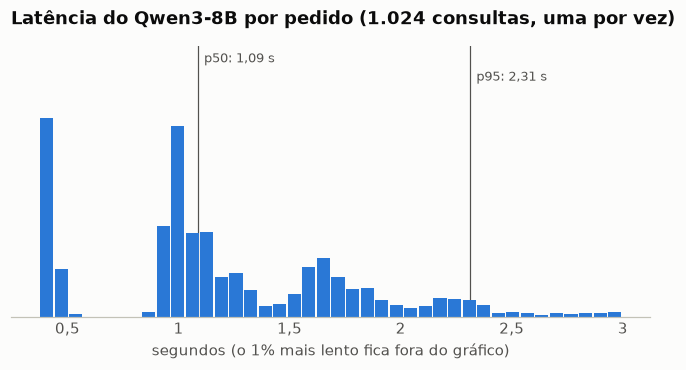

Latência pelo tamanho da resposta: cada pico do histograma é um número de entidades


,consultas,latência mediana (s)
entidades na resposta,,
nenhuma,209,"0,42"
1,497,"1,03"
2,251,"1,72"
3 ou mais,67,"2,37"


,"Qwen3-8B (aberto, local)","Claude Haiku 5.5 (fechado, API)",Rede do zero (Etapa 4b)
Latência p50,"1,09 s","0,85 s","1,2 ms"
Latência p95,"2,31 s","1,00 s","1,6 ms"
Custo por mil pedidos,sem custo por pedido; usa a GPU da máquina,"US$ 0,114 (direto); US$ 0,057 (em lote)",sem custo por pedido; 1 núcleo de CPU
Rotular o treino,"1 h 49 min de GPU (0,57 s por pedido, em lotes de 6)","US$ 0,66, em lote",não se aplica
Memória,"6,1 GB na placa (pico de 8,3 GB ao rotular)",nenhuma nesta máquina,20 MB em disco


In [16]:
pasta_latencia = etapa5b.pasta_das_respostas(escolhido, "latencia")
tempos = np.load(pasta_latencia / "tempos_ms.npy")
meta_latencia = json.loads((pasta_latencia / "meta.json").read_text(encoding="utf-8"))
latencia = eficiencia.resumir_latencia(tempos)
p99 = latencia["latencia_p99_ms"]
fig, ax = visual.histograma(
    tempos[tempos <= p99] / 1000, f"Latência do {PROFESSOR} por pedido ({n(len(tempos))} consultas, uma por vez)", "segundos (o 1% mais lento fica fora do gráfico)",
    marcas={f"p50: {num(latencia['latencia_p50_ms'] / 1000, 2)} s": latencia["latencia_p50_ms"] / 1000,
            f"p95: {num(latencia['latencia_p95_ms'] / 1000, 2)} s": latencia["latencia_p95_ms"] / 1000},
)
visual.salvar(fig, PASTA, "latencia")
plt.show()

# o histograma tem vários picos: cada entidade a mais na resposta são mais tokens para gerar, um por vez
def entidades_na_resposta(registro):
    try:
        return min(len(json.loads(registro["texto"])["slots"]), 3)
    except (TypeError, ValueError, KeyError):
        return -1


quantas = np.array([entidades_na_resposta(r) for r in claude.ler_em_ordem(pasta_latencia / "respostas.jsonl")])
por_entidades = pd.DataFrame([
    {"entidades na resposta": {0: "nenhuma", 1: "1", 2: "2", 3: "3 ou mais"}[k], "consultas": n((quantas == k).sum()),
     "latência mediana (s)": num(np.median(tempos[quantas == k]) / 1000, 2)}
    for k in (0, 1, 2, 3) if (quantas == k).any()
]).set_index("entidades na resposta")
print("Latência pelo tamanho da resposta: cada pico do histograma é um número de entidades")
display(por_entidades)

resultados_5a = pd.read_csv(ETAPA5A / "resultados.csv").query("particao == 'test'").iloc[0]
resultados_rede = resultados.carregar(ENTREGAS / "04b_intencao").query("particao == 'test'").iloc[0]
custo_5a = json.loads((ETAPA5A / "custo.json").read_text(encoding="utf-8"))
metas = {c: json.loads((etapa5b.pasta_das_respostas(escolhido, c) / "meta.json").read_text(encoding="utf-8")) for c in ("dev", "test", "train")}
gpu_do_professor = sum(m["segundos_de_gpu"] for m in metas.values())
gpu_dos_outros = sum(metas_dev[a]["segundos_de_gpu"] for a in candidatos if a != escolhido)
em_lote = gpu_do_professor / sum(m["pedidos"] for m in metas.values())

pd.DataFrame({
    f"{PROFESSOR} (aberto, local)": {
        "Latência p50": f"{num(latencia['latencia_p50_ms'] / 1000, 2)} s", "Latência p95": f"{num(latencia['latencia_p95_ms'] / 1000, 2)} s",
        "Custo por mil pedidos": "sem custo por pedido; usa a GPU da máquina",
        "Rotular o treino": f"{horas(metas['train']['segundos_de_gpu'])} de GPU ({num(metas['train']['segundos_de_gpu'] / metas['train']['pedidos'], 2)} s por pedido, em lotes de {metas['train']['lote']})",
        "Memória": f"{num(meta_latencia['vram_do_modelo_gb'], 1)} GB na placa (pico de {num(max(m['vram_de_pico_gb'] for m in metas.values()), 1)} GB ao rotular)",
    },
    f"{FECHADO} (fechado, API)": {
        "Latência p50": f"{num(resultados_5a['latencia_p50_ms'] / 1000, 2)} s", "Latência p95": f"{num(resultados_5a['latencia_p95_ms'] / 1000, 2)} s",
        "Custo por mil pedidos": f"US$ {num(resultados_5a['custo_por_mil_pedidos_usd'], 3)} (direto); US$ {num(resultados_5a['custo_por_mil_pedidos_em_lote_usd'], 3)} (em lote)",
        "Rotular o treino": f"US$ {num(custo_5a['partes']['Lote de treino']['dolares'], 2)}, em lote",
        "Memória": "nenhuma nesta máquina",
    },
    "Rede do zero (Etapa 4b)": {
        "Latência p50": f"{num(resultados_rede['latencia_p50_ms'], 1)} ms", "Latência p95": f"{num(resultados_rede['latencia_p95_ms'], 1)} ms",
        "Custo por mil pedidos": "sem custo por pedido; 1 núcleo de CPU", "Rotular o treino": "não se aplica",
        "Memória": f"{num(resultados_rede['bytes'] / 1e6, 0)} MB em disco",
    },
})

In [17]:
print(f"Tempo de GPU da etapa: {horas(gpu_do_professor)} do professor escolhido (dev, teste e treino) e {horas(gpu_dos_outros)} dos candidatos não escolhidos (dev).")
print(f"Máquina: {meta_latencia['gpu']}, {meta_latencia['cpu']}. Modelo com {num(parametros[escolhido] / 1e9, 1)} bilhões de parâmetros, em {meta_latencia['quantizacao']}.")

Tempo de GPU da etapa: 2 h 34 min do professor escolhido (dev, teste e treino) e 25 min dos candidatos não escolhidos (dev).
Máquina: NVIDIA GeForce RTX 3080, 13th Gen Intel(R) Core(TM) i7-13700K. Modelo com 8,2 bilhões de parâmetros, em 4 bits (NF4, bitsandbytes).


## 9. Entrega

In [18]:
# 1. Para o aluno B1: o treino rotulado, nas colunas que o treino da rede lê
rotulado.to_parquet(PASTA / "rotulos_treino.parquet", index=False)

# 2. Para o aluno B2: as log-probabilidades de intenção, alinhadas às linhas do treino
np.save(PASTA / "logits_treino.npy", logp_treino)
np.save(PASTA / "logits_dev.npy", logp_dev.astype(np.float32))
np.save(PASTA / "logits_test.npy", logp_teste)
(PASTA / "intencoes.json").write_text(json.dumps(intents, indent=1) + "\n", encoding="utf-8")

# 3. As respostas em dev e teste, no formato da régua
for apelido in candidatos:
    salvar_previsoes(PASTA / "previsoes" / f"{apelido}_dev.parquet", dev["id"], lidos_dev[apelido][0])
salvar_previsoes(PASTA / "previsoes" / f"{escolhido}_test.parquet", teste["id"], aberto_teste)

# 4. As respostas brutas e as medidas (horas de GPU não se refazem de graça)
for apelido in candidatos:
    origem = etapa5b.PASTA / apelido
    if origem.exists():
        shutil.copytree(origem, PASTA / "respostas" / apelido, dirs_exist_ok=True)
if (etapa5b.PASTA / "colchete_forcado.json").exists():
    shutil.copy(etapa5b.PASTA / "colchete_forcado.json", PASTA / "respostas" / "colchete_forcado.json")

# 5. A tabela de resultados
linhas_resultado = [
    resultados.registrar(f"{PROFESSOR} em 4 bits (10 exemplos de 299 rótulos)", particao, gabarito[particao], do_professor[particao], tempos_ms=tempos,
                         parametros=parametros[escolhido], modelo=etapa5b.CANDIDATOS[escolhido]["id"],
                         vram_gb=meta_latencia["vram_do_modelo_gb"], gpu=meta_latencia["gpu"], segundos_por_pedido_em_lote=em_lote)
    for particao in ("dev", "test")
] + [
    resultados.registrar(f"{etapa5b.CANDIDATOS[a]['nome']} em 4 bits (candidato não escolhido)", "dev", ouro_dev, lidos_dev[a][0],
                         parametros=parametros[a], modelo=etapa5b.CANDIDATOS[a]["id"], vram_gb=metas_dev[a]["vram_do_modelo_gb"], gpu=metas_dev[a]["gpu"])
    for a in candidatos if a != escolhido
]
resultados.salvar(linhas_resultado, PASTA)
pd.concat({f"{p} · {ref}": t.loc[list(qualidade.METRICAS)] for p in ("dev", "test") for ref, t in contra[p].items()},
          names=["comparacao", "metrica"]).to_csv(PASTA / "comparacoes.csv")
(PASTA / "escolha.json").write_text(json.dumps({
    "etapa": "05b_professor_aberto", "gerado_em": date.today().isoformat(), "escolhido": escolhido, "modelo": etapa5b.CANDIDATOS[escolhido]["id"],
    "regra": "do mais barato para o mais caro; um candidato mais caro só toma o lugar se o exact match em dev for distinguivelmente maior (IC95 da diferença pareada acima de zero)",
    "candidatos": {a: {"nome": etapa5b.CANDIDATOS[a]["nome"], **{m: medidas_dev[a][m] for m in qualidade.METRICAS}} for a in candidatos},
    "disputas": disputas, "conferencia_dos_atalhos": conferencia,
    "calibracao_em_dev": {"confianca_media": float(confianca_dev.mean()), "acuracia": float(acertou_dev.mean()), "ece": ece},
}, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

relido = pd.read_parquet(PASTA / "rotulos_treino.parquet")
relido_ok = [Previsao.de_tags(i, list(t)) for i, t in zip(relido["intent"], relido["tags"])] == aberto_treino
logits_relidos = np.load(PASTA / "logits_treino.npy")
# nos pedidos com rótulo aproveitável, a intenção do rótulo é a de maior pontuação (as pontuações são gravadas com 4 casas)
com_rotulo = relido["valido"].to_numpy()
do_rotulo = np.array([coluna.get(intent, 0) for intent in relido["intent"]])
logits_ok = logits_relidos.shape == (len(treino), len(intents)) and bool(
    np.all(logits_relidos[com_rotulo, do_rotulo[com_rotulo]] >= logits_relidos[com_rotulo].max(axis=1) - 1e-4))
print("Treino rotulado relido do disco reproduz as respostas do professor:", "sim" if relido_ok else "NÃO")
print("A intenção de maior pontuação em cada linha dos logits é a intenção do rótulo:", "sim" if logits_ok else "NÃO")

Treino rotulado relido do disco reproduz as respostas do professor: sim
A intenção de maior pontuação em cada linha dos logits é a intenção do rótulo: sim


### Critério de pronto

In [19]:
sem_pontuacao = sum(len(r.get("logp") or []) != len(intents) for c in lidos.values() for r in c[2])
pronto = pd.Series({
    f"Professor escolhido em dev pela regra escrita antes ({len(candidatos)} candidatos)": len(candidatos) >= 2 and escolhido in candidatos,
    f"Todo pedido tem resposta gravada e as 60 pontuações ({n(total['pedidos'])} pedidos)": int(total["sem registro"]) == 0 and sem_pontuacao == 0,
    "Na régua, com intervalo, pareado com as referências e com o professor fechado": all(len(contra[p]) == 3 for p in ("dev", "test")),
    "Atalhos de cálculo conferidos contra a conta direta (mesma intenção em todos; probabilidades a menos de 1 ponto)":
        direta["mesma_intencao"] == direta["pedidos"] and direta["maior_diferenca_de_probabilidade"] < 0.01 and biblioteca["mesma_resposta_depois_de_lida"] == q,
    "Rótulos e logits gravados no formato que a destilação lê": bool(relido_ok and logits_ok),
}).map({True: "sim", False: "NÃO"}).rename("atendido").to_frame()
assert (pronto["atendido"] == "sim").all()
pronto

,atendido
Professor escolhido em dev pela regra escrita antes (3 candidatos),sim
Todo pedido tem resposta gravada e as 60 pontuações (16.521 pedidos),sim
"Na régua, com intervalo, pareado com as referências e com o professor fechado",sim
Atalhos de cálculo conferidos contra a conta direta (mesma intenção em todos; probabilidades a menos de 1 ponto),sim
Rótulos e logits gravados no formato que a destilação lê,sim


## 10. Resposta

O resumo abaixo é gerado a partir dos números calculados neste notebook e gravado em `entregas/05b_professor_aberto/RESUMO.md`.

In [20]:
tabela_candidatos = "\n".join(
    f"| {etapa5b.CANDIDATOS[a]['nome']} | {num(metas_dev[a]['vram_do_modelo_gb'], 1)} | {num(metas_dev[a]['segundos_de_gpu'] / metas_dev[a]['pedidos'], 2)} | "
    + " | ".join(pts(medidas_dev[a][m]) for m in qualidade.METRICAS) + f" | {'sim' if a == escolhido else ''} |"
    for a in candidatos
)
tabela_disputas = "\n".join(
    f"| {etapa5b.CANDIDATOS[a]['nome']} | {etapa5b.CANDIDATOS[d['contra']]['nome']} | {com_intervalo(d)} | {'sim' if d['ic_min'] > 0 else 'não'} |" for a, d in disputas.items()
)
tabela_teste = "\n".join(
    f"| {qualidade.NOMES[m]} | {valor_com_intervalo(medida_teste.loc[m])} | "
    + " | ".join(f"{pts(t.loc[m, 'a'])} · {com_intervalo(t.loc[m])}" for t in contra["test"].values()) + " |"
    for m in qualidade.METRICAS
)
tabela_destinos = "\n".join(
    f"| {nomes_dos_destinos[d]} | " + " | ".join(f"{n(round(destinos.loc[d, c]))} ({pts(destinos.loc[d, c] / entidades_em_dev)}%)" for c in destinos.columns) + " |"
    for d in destinos.index
)
tabela_faixas = "\n".join(
    f"| {pts(l['de'], 0)}% a {pts(l['ate'], 0)}% | {n(l['pedidos'])} | {pts(l['confianca'])}% | {pts(l['acuracia'])}% |" for _, l in faixas.iterrows()
)

resumo = f"""# Etapa 5b · O professor aberto: resumo da entrega

**Pergunta.** Quão bem uma LLM aberta, rodando nesta máquina, resolve a tarefa, e o que ela entrega que a fechada não entrega?

**Resposta.** O professor aberto é o **{PROFESSOR}**, em 4 bits, escolhido em `dev` entre {len(candidatos)} candidatos. Ele acrescenta {dif(contra_299["diferenca"])} pontos de exact match à linha de base treinada com os mesmos {len(demonstracoes)} rótulos (em `dev`). No teste ele faz {pts(medida_teste.loc['intent_acc', 'valor'])}% de acurácia de intenção, {pts(medida_teste.loc['slot_f1', 'valor'])}% de F1 de entidades e {pts(medida_teste.loc['exact_match', 'valor'])}% de exact match. Contra o professor fechado ({FECHADO}), fica {posicao(contra_fechado.loc['intent_acc'])} em intenção ({com_intervalo(contra_fechado.loc['intent_acc'])}), {posicao(contra_fechado.loc['slot_f1'])} em entidades ({com_intervalo(contra_fechado.loc['slot_f1'])}) e {posicao(contra_fechado.loc['exact_match'])} em exact match ({com_intervalo(contra_fechado.loc['exact_match'])}). O que ele entrega a mais são as **probabilidades das 60 intenções** para cada pedido: a intenção certa está em primeiro lugar em {pts(entre_as_k[1])}% dos pedidos de `dev`, e entre as 3 mais prováveis em {pts(entre_as_k[3])}%. Cada resposta leva {num(latencia['latencia_p50_ms'] / 1000, 2)} s (mediana) na placa desta máquina; rotular o treino levou {horas(metas['train']['segundos_de_gpu'])} de GPU, sem custo por pedido.

## A escolha do professor (dev)

Regra, escrita antes: do mais barato para o mais caro, um candidato só toma o lugar do anterior se o exact match dele em `dev` for distinguivelmente maior (intervalo de 95% da diferença pareada todo acima de zero).

| Candidato (4 bits) | Memória na placa (GB) | s por pedido, em lote | {" | ".join(qualidade.NOMES[m] for m in qualidade.METRICAS)} | Escolhido |
|---|---|---|---|---|---|---|---|
{tabela_candidatos}

| Desafiante | Titular | Diferença de exact match (intervalo de 95%) | Toma o lugar |
|---|---|---|---|
{tabela_disputas}

## Qualidade no teste

Cada coluna de referência traz o valor da referência e, depois do ponto, a diferença professor aberto − referência com intervalo de 95%.

| Métrica | {PROFESSOR} (intervalo de 95%) | {" | ".join(contra["test"])} |
|---|---|---|---|---|
{tabela_teste}

![Os dois professores](figuras/os_dois_professores.png)

## O que voltou do modelo (dev, teste e treino somados)

- Respostas sem aproveitamento: {n(sem_uso)} de {n(total['pedidos'])}. Entidades descartadas na leitura: {n(perdidas)} de {n(total['entidades devolvidas'])} ({pts(perdidas / total['entidades devolvidas'], 2)}%), {n(total['tipo fora da lista'])} por tipo fora da lista e {n(total['texto que não está no pedido'])} por texto que não está no pedido. A intenção nunca sai da lista.

## Onde erra (dev)

- Os dois professores dão exatamente a mesma resposta em {pts(mesma_resposta)}% dos pedidos de `dev`; em {pts(acordo.iloc[1])}% só o fechado acerta tudo e em {pts(acordo.iloc[2])}% só o aberto.

| Destino de cada entidade dos rótulos humanos | {" | ".join(destinos.columns)} |
|---|---|---|---|
{tabela_destinos}

## O que os logits trazem (dev)

| Faixa de confiança | Pedidos | Confiança média | Acurácia |
|---|---|---|---|
{tabela_faixas}

- Confiança média de {pts(confianca_dev.mean())}% para uma acurácia de {pts(acertou_dev.mean())}%: erro de calibração esperado (ECE) de {pts(ece)} pontos.
- Intenção certa entre as k mais prováveis: {", ".join(f"k={k}: {pts(v)}%" for k, v in entre_as_k.items())}.
- Nos {n(erros.sum())} erros de intenção, a certa é a 2ª colocada em {pts((colocacao_nos_erros == 2).mean())}%.

![Calibração](figuras/calibracao.png)

![Entre as k](figuras/entre_as_k.png)

## Um detalhe de formato

Na primeira versão, o texto forçado depois da intenção ia até o colchete que abre a lista (`", "slots": [`). Para uma lista vazia o modelo escreve `[]` como um token só, e com o `[` já escrito ele errava o fechamento e devolvia entidades de sobra. Forçar só até `"slots":` levou o exact match do {PROFESSOR} em `dev` de {pts(antes[escolhido]['exact_match'])}% para {pts(medidas_dev[escolhido]['exact_match'])}% ({dif(ganho_do_escolhido)} pontos).

## Conferência dos atalhos de cálculo

- Pontuação com os atalhos contra 60 passadas inteiras por pedido ({direta['pedidos']} pedidos): maior diferença de probabilidade de {pts(direta['maior_diferenca_de_probabilidade'], 2)} ponto percentual; mesma intenção em {direta['mesma_intencao']} de {direta['pedidos']}.
- Geração própria contra a função `generate` da biblioteca ({q} pedidos): mesma resposta, depois de lida, em {biblioteca['mesma_resposta_depois_de_lida']}.
- Em lotes de {conferencia['lote']} contra um pedido por vez ({q} pedidos): mesma intenção em {lote['mesma_intencao']}; mesma resposta em {lote['mesma_resposta_depois_de_lida']}; a probabilidade de uma intenção chega a mudar {pts(lote['maior_diferenca_de_probabilidade'])} pontos num caso de quase empate. A diferença vem da conta em 16 bits, não dos atalhos.

## Latência e tempo de GPU

- Latência, uma consulta por vez, {n(len(tempos))} consultas: p50 {num(latencia['latencia_p50_ms'] / 1000, 2)} s, p95 {num(latencia['latencia_p95_ms'] / 1000, 2)} s. Ela cresce com o tamanho da resposta: {por_entidades.iloc[0]['latência mediana (s)']} s sem entidades e {por_entidades.iloc[-1]['latência mediana (s)']} s com {por_entidades.index[-1]}. O professor fechado: p50 {num(resultados_5a['latencia_p50_ms'] / 1000, 2)} s. A rede do zero: {num(resultados_rede['latencia_p50_ms'], 1)} ms.
- Em lotes de {metas['train']['lote']}: {num(em_lote, 2)} s por pedido. Tempo de GPU: {horas(gpu_do_professor)} do professor escolhido (dev, teste e treino) e {horas(gpu_dos_outros)} dos candidatos não escolhidos.
- Memória: {num(meta_latencia['vram_do_modelo_gb'], 1)} GB na placa para o modelo. Máquina: {meta_latencia['gpu']}.

![Latência](figuras/latencia.png)

## Limites

- **Os logits são só da intenção.** As entidades são texto gerado; não há probabilidade por palavra do pedido.
- **4 bits.** O modelo roda com os pesos quantizados para caber na placa; em precisão cheia ele pode ser um pouco melhor.
- **Lotes em 16 bits.** Processar pedidos juntos muda a resposta em uma pequena parte deles, quando dois tokens estão quase empatados (ver a conferência).
- **Três candidatos, um prompt.** Modelos maiores não cabem na placa de 10 GB; o prompt é o mesmo da Etapa 5a, sem ajuste por modelo.
- **A escolha usou `dev`.** O valor em `dev` do professor escolhido é levemente otimista; o do teste não.
- **O modelo pode conhecer o MASSIVE**, como na Etapa 5a.

## Para a Etapa 6

- Aluno B1: `rotulos_treino.parquet` (as colunas que o treino da rede lê; `valido` marca pedidos sem rótulo aproveitável).
- Aluno B2: `logits_treino.npy`, {n(logp_treino.shape[0])} × {logp_treino.shape[1]}, na ordem das linhas do treino e das intenções de `intencoes.json`. São log-probabilidades: para usar com temperatura T, divide-se por T antes do softmax. As entidades do B2 vêm de `rotulos_treino.parquet`.
- A suavização de rótulos da Etapa 4b não se aplica ao B2 (o alvo já é uma distribuição).

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `rotulos_treino.parquet` | O treino rotulado pelo professor aberto |
| `logits_treino.npy`, `logits_dev.npy`, `logits_test.npy`, `intencoes.json` | As log-probabilidades das 60 intenções e a ordem das colunas |
| `escolha.json` | A regra, os candidatos, as disputas, a conferência e a calibração |
| `previsoes/` | As respostas de cada candidato em dev e do escolhido no teste, no formato da régua |
| `respostas/` | As respostas brutas de cada modelo, com as pontuações; latência e conferência |
| `resultados.csv`, `comparacoes.csv` | O professor e os candidatos na régua; cada comparação pareada |
| `figuras/` | Os gráficos deste notebook |
| `05b_professor_aberto.html` | Este notebook executado, para leitura |
"""
(PASTA / "RESUMO.md").write_text(resumo, encoding="utf-8")
display(Markdown(resumo))

# Etapa 5b · O professor aberto: resumo da entrega

**Pergunta.** Quão bem uma LLM aberta, rodando nesta máquina, resolve a tarefa, e o que ela entrega que a fechada não entrega?

**Resposta.** O professor aberto é o **Qwen3-8B**, em 4 bits, escolhido em `dev` entre 3 candidatos. Ele acrescenta +23,0 pontos de exact match à linha de base treinada com os mesmos 299 rótulos (em `dev`). No teste ele faz 77,6% de acurácia de intenção, 55,7% de F1 de entidades e 43,2% de exact match. Contra o professor fechado (Claude Haiku 5.5), fica abaixo em intenção (−5,9 (−7,2 a −4,5)), abaixo em entidades (−10,4 (−11,9 a −8,9)) e abaixo em exact match (−10,8 (−12,4 a −9,1)). O que ele entrega a mais são as **probabilidades das 60 intenções** para cada pedido: a intenção certa está em primeiro lugar em 77,4% dos pedidos de `dev`, e entre as 3 mais prováveis em 88,7%. Cada resposta leva 1,09 s (mediana) na placa desta máquina; rotular o treino levou 1 h 49 min de GPU, sem custo por pedido.

## A escolha do professor (dev)

Regra, escrita antes: do mais barato para o mais caro, um candidato só toma o lugar do anterior se o exact match dele em `dev` for distinguivelmente maior (intervalo de 95% da diferença pareada todo acima de zero).

| Candidato (4 bits) | Memória na placa (GB) | s por pedido, em lote | Acurácia de intenção | Macro-F1 de intenção | F1 de entidades | Exact match | Escolhido |
|---|---|---|---|---|---|---|---|
| Qwen3-4B | 2,7 | 0,39 | 73,5 | 73,3 | 53,5 | 34,9 |  |
| GAIA 4B (CEIA-UFG) | 3,2 | 0,34 | 71,1 | 71,7 | 50,7 | 38,6 |  |
| Qwen3-8B | 6,1 | 0,54 | 77,4 | 78,3 | 58,0 | 43,2 | sim |

| Desafiante | Titular | Diferença de exact match (intervalo de 95%) | Toma o lugar |
|---|---|---|---|
| GAIA 4B (CEIA-UFG) | Qwen3-4B | +3,7 (+1,6 a +5,9) | sim |
| Qwen3-8B | GAIA 4B (CEIA-UFG) | +4,6 (+2,5 a +6,5) | sim |

## Qualidade no teste

Cada coluna de referência traz o valor da referência e, depois do ponto, a diferença professor aberto − referência com intervalo de 95%.

| Métrica | Qwen3-8B (intervalo de 95%) | Linha de base com 11.514 rótulos | Rede do zero com 11.514 rótulos | Claude Haiku 5.5 (professor fechado) |
|---|---|---|---|---|
| Acurácia de intenção | 77,6 (76,1 a 79,1) | 84,6 · −7,0 (−8,5 a −5,5) | 84,4 · −6,8 (−8,2 a −5,4) | 83,5 · −5,9 (−7,2 a −4,5) |
| Macro-F1 de intenção | 76,6 (74,7 a 79,2) | 81,4 · −4,8 (−7,3 a −2,1) | 82,8 · −6,2 (−8,2 a −4,0) | 82,1 · −5,5 (−7,2 a −3,8) |
| F1 de entidades | 55,7 (53,9 a 57,4) | 47,8 · +7,9 (+5,7 a +10,1) | 73,6 · −18,0 (−19,7 a −16,2) | 66,1 · −10,4 (−11,9 a −8,9) |
| Exact match | 43,2 (41,5 a 45,0) | 45,2 · −2,0 (−4,1 a +0,1) | 62,5 · −19,2 (−21,1 a −17,5) | 54,0 · −10,8 (−12,4 a −9,1) |

![Os dois professores](figuras/os_dois_professores.png)

## O que voltou do modelo (dev, teste e treino somados)

- Respostas sem aproveitamento: 18 de 16.521. Entidades descartadas na leitura: 1.140 de 20.050 (5,69%), 743 por tipo fora da lista e 397 por texto que não está no pedido. A intenção nunca sai da lista.

## Onde erra (dev)

- Os dois professores dão exatamente a mesma resposta em 53,1% dos pedidos de `dev`; em 16,4% só o fechado acerta tudo e em 4,8% só o aberto.

| Destino de cada entidade dos rótulos humanos | Qwen3-8B | Claude Haiku 5.5 | Rede do zero (média de 3 sementes) |
|---|---|---|---|
| Certa | 1.259 (62,9%) | 1.439 (72,0%) | 1.531 (76,5%) |
| Limite diferente | 242 (12,1%) | 223 (11,2%) | 181 (9,0%) |
| Tipo diferente | 164 (8,2%) | 105 (5,2%) | 68 (3,4%) |
| Tipo e limite diferentes | 117 (5,9%) | 60 (3,0%) | 59 (2,9%) |
| Faltou | 218 (10,9%) | 173 (8,6%) | 162 (8,1%) |
| A mais (não está nos rótulos) | 565 (28,2%) | 368 (18,4%) | 205 (10,3%) |

## O que os logits trazem (dev)

| Faixa de confiança | Pedidos | Confiança média | Acurácia |
|---|---|---|---|
| 20% a 30% | 1 | 26,3% | 0,0% |
| 30% a 40% | 6 | 35,5% | 16,7% |
| 40% a 50% | 21 | 46,2% | 19,0% |
| 50% a 60% | 45 | 55,4% | 24,4% |
| 60% a 70% | 49 | 65,0% | 32,7% |
| 70% a 80% | 46 | 75,9% | 37,0% |
| 80% a 90% | 71 | 85,2% | 36,6% |
| 90% a 100% | 1.794 | 99,6% | 83,6% |

- Confiança média de 95,9% para uma acurácia de 77,4%: erro de calibração esperado (ECE) de 18,5 pontos.
- Intenção certa entre as k mais prováveis: k=1: 77,4%, k=2: 85,6%, k=3: 88,7%, k=5: 92,6%, k=10: 95,9%.
- Nos 459 erros de intenção, a certa é a 2ª colocada em 36,4%.

![Calibração](figuras/calibracao.png)

![Entre as k](figuras/entre_as_k.png)

## Um detalhe de formato

Na primeira versão, o texto forçado depois da intenção ia até o colchete que abre a lista (`", "slots": [`). Para uma lista vazia o modelo escreve `[]` como um token só, e com o `[` já escrito ele errava o fechamento e devolvia entidades de sobra. Forçar só até `"slots":` levou o exact match do Qwen3-8B em `dev` de 28,9% para 43,2% (+14,3 pontos).

## Conferência dos atalhos de cálculo

- Pontuação com os atalhos contra 60 passadas inteiras por pedido (8 pedidos): maior diferença de probabilidade de 0,11 ponto percentual; mesma intenção em 8 de 8.
- Geração própria contra a função `generate` da biblioteca (32 pedidos): mesma resposta, depois de lida, em 32.
- Em lotes de 6 contra um pedido por vez (32 pedidos): mesma intenção em 32; mesma resposta em 31; a probabilidade de uma intenção chega a mudar 9,8 pontos num caso de quase empate. A diferença vem da conta em 16 bits, não dos atalhos.

## Latência e tempo de GPU

- Latência, uma consulta por vez, 1.024 consultas: p50 1,09 s, p95 2,31 s. Ela cresce com o tamanho da resposta: 0,42 s sem entidades e 2,37 s com 3 ou mais. O professor fechado: p50 0,85 s. A rede do zero: 1,2 ms.
- Em lotes de 6: 0,56 s por pedido. Tempo de GPU: 2 h 34 min do professor escolhido (dev, teste e treino) e 25 min dos candidatos não escolhidos.
- Memória: 6,1 GB na placa para o modelo. Máquina: NVIDIA GeForce RTX 3080.

![Latência](figuras/latencia.png)

## Limites

- **Os logits são só da intenção.** As entidades são texto gerado; não há probabilidade por palavra do pedido.
- **4 bits.** O modelo roda com os pesos quantizados para caber na placa; em precisão cheia ele pode ser um pouco melhor.
- **Lotes em 16 bits.** Processar pedidos juntos muda a resposta em uma pequena parte deles, quando dois tokens estão quase empatados (ver a conferência).
- **Três candidatos, um prompt.** Modelos maiores não cabem na placa de 10 GB; o prompt é o mesmo da Etapa 5a, sem ajuste por modelo.
- **A escolha usou `dev`.** O valor em `dev` do professor escolhido é levemente otimista; o do teste não.
- **O modelo pode conhecer o MASSIVE**, como na Etapa 5a.

## Para a Etapa 6

- Aluno B1: `rotulos_treino.parquet` (as colunas que o treino da rede lê; `valido` marca pedidos sem rótulo aproveitável).
- Aluno B2: `logits_treino.npy`, 11.514 × 60, na ordem das linhas do treino e das intenções de `intencoes.json`. São log-probabilidades: para usar com temperatura T, divide-se por T antes do softmax. As entidades do B2 vêm de `rotulos_treino.parquet`.
- A suavização de rótulos da Etapa 4b não se aplica ao B2 (o alvo já é uma distribuição).

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `rotulos_treino.parquet` | O treino rotulado pelo professor aberto |
| `logits_treino.npy`, `logits_dev.npy`, `logits_test.npy`, `intencoes.json` | As log-probabilidades das 60 intenções e a ordem das colunas |
| `escolha.json` | A regra, os candidatos, as disputas, a conferência e a calibração |
| `previsoes/` | As respostas de cada candidato em dev e do escolhido no teste, no formato da régua |
| `respostas/` | As respostas brutas de cada modelo, com as pontuações; latência e conferência |
| `resultados.csv`, `comparacoes.csv` | O professor e os candidatos na régua; cada comparação pareada |
| `figuras/` | Os gráficos deste notebook |
| `05b_professor_aberto.html` | Este notebook executado, para leitura |


In [21]:
arquivos = sorted(p for p in PASTA.rglob("*") if p.is_file())
pd.DataFrame(
    {"tamanho (KB)": [round(p.stat().st_size / 1024, 1) for p in arquivos]},
    index=[str(p.relative_to(RAIZ)) for p in arquivos],
)

,tamanho (KB)
entregas/05b_professor_aberto/RESUMO.md,7.9
entregas/05b_professor_aberto/comparacoes.csv,3.8
entregas/05b_professor_aberto/escolha.json,2.1
entregas/05b_professor_aberto/figuras/calibracao.png,53.7
entregas/05b_professor_aberto/figuras/entre_as_k.png,55.5
entregas/05b_professor_aberto/figuras/escolha_do_professor.png,36.7
entregas/05b_professor_aberto/figuras/latencia.png,30.9
entregas/05b_professor_aberto/figuras/os_dois_professores.png,57.5
entregas/05b_professor_aberto/intencoes.json,1.1
entregas/05b_professor_aberto/logits_dev.npy,476.6
